# Task C: Improved Seq2Seq Survival-Curve Pipeline

This notebook upgrades the first `task_c` baseline in three ways:

1. A stronger monotone decoder with explicit step embeddings.
2. Patience-based early stopping plus learning-rate scheduling.
3. A mean-curve baseline so the learned model is judged against something concrete.

The goal remains the same: from a trajectory prefix of length `T=100`, predict a case-level survival curve over future times.


In [14]:
import copy
import random
from pathlib import Path

import h5py
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.optim.lr_scheduler import ReduceLROnPlateau
from torch.utils.data import DataLoader, Dataset

SEED = 42
GROUP_SIZE = 8
T_IN = 100
FUTURE_TIMES = np.array([200, 400, 600, 800, 1000], dtype=np.float32)
NUM_FEATURES = 15

BATCH_SIZE = 128
HIDDEN_DIM = 96
ENCODER_TYPE = "gru"  # one of: "gru", "cnn", "tcn"
GROUP_REDUCE = "mean"  # "mean" or "first"
DROPOUT = 0.20
EPOCHS = 80
LR = 1e-3
WEIGHT_DECAY = 2e-4
GRAD_CLIP_NORM = 1.0
TEST_RATIO = 0.2
VAL_RATIO = 0.1  # interpreted as a fraction of total cases, not of the remaining train pool
EARLY_STOPPING_PATIENCE = 12
EARLY_STOPPING_MIN_DELTA = 1e-4
SCHEDULER_PATIENCE = 4
SCHEDULER_FACTOR = 0.5
TEACHER_FORCING_RATIO = 0.0

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", DEVICE)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DATASET_DIR = Path("./dataset")
RESULT_PATHS = [
    DATASET_DIR / "results_batch_00_sampling_0.hdf5",
    DATASET_DIR / "results_batch_01_sampling_0.hdf5",
    DATASET_DIR / "results_batch_02_sampling_0.hdf5",
    DATASET_DIR / "results_batch_03_sampling_0.hdf5",
    DATASET_DIR / "results_batch_04_sampling_0.hdf5",
]
LABELS_PATH = DATASET_DIR / "completed_systems_sampling_0.txt"


Using device: cuda


In [15]:
RESULT_KEYS = [
    "aratios_complete",
    "mratios_complete",
    "eccs_complete",
    "incs_complete",
    "APs_complete",
    "LANs_complete",
]


def load_one_h5(path, keys, T=None, dtype=np.float32):
    sl = slice(None) if T is None else slice(0, T)
    out = {}
    with h5py.File(path, "r") as f:
        for key in keys:
            out[key] = f[key][:, sl, ...].astype(dtype)
    return out


def load_all_batches(paths, keys, T=None, dtype=np.float32):
    shards = [load_one_h5(path, keys=keys, T=T, dtype=dtype) for path in paths]
    return {key: np.concatenate([shard[key] for shard in shards], axis=0) for key in keys}


def sincos(x: np.ndarray) -> np.ndarray:
    x = x.astype(np.float32)
    return np.concatenate([np.sin(x), np.cos(x)], axis=-1)


def build_orbital_feature_stack(data: dict) -> np.ndarray:
    ar = data["aratios_complete"].astype(np.float32)
    mr = data["mratios_complete"].astype(np.float32)
    ec = data["eccs_complete"].astype(np.float32)
    inc = data["incs_complete"].astype(np.float32)
    ap = sincos(data["APs_complete"])
    lan = sincos(data["LANs_complete"])
    X = np.concatenate([ar, mr, ec, inc, ap, lan], axis=-1)
    assert X.shape[-1] == NUM_FEATURES, X.shape
    return X.astype(np.float32)


data = load_all_batches(RESULT_PATHS, keys=RESULT_KEYS, T=T_IN)
X_traj = build_orbital_feature_stack(data)
print("Trajectory feature tensor:", X_traj.shape)


Trajectory feature tensor: (40000, 100, 15)


In [16]:
labels = pd.read_csv(
    LABELS_PATH,
    sep=r"\s+",
    header=None,
    names=["index", "num_batch", "time_unbound", "ignore_other_than_minus1", "diagnosis"],
)

labels = labels.astype(
    {
        "index": "int64",
        "num_batch": "int64",
        "time_unbound": "float32",
        "ignore_other_than_minus1": "float32",
        "diagnosis": "int64",
    }
)

# Match the sample order used in task_b.ipynb.
labels = labels.sort_values(["num_batch", "index"], ascending=True).reset_index(drop=True)
labels["raw_case_id"] = np.arange(len(labels)) // GROUP_SIZE

assert len(labels) == len(X_traj), (len(labels), len(X_traj))

# Keep finite trajectory prefixes only.
finite_mask = np.isfinite(X_traj).all(axis=(1, 2))
X_traj = X_traj[finite_mask]
labels = labels.loc[finite_mask].reset_index(drop=True)

# Cleaning can break a perturbation set, so keep complete 8-sample cases only.
case_counts = labels["raw_case_id"].value_counts().sort_index()
complete_case_ids = case_counts[case_counts == GROUP_SIZE].index.to_numpy()
complete_mask = labels["raw_case_id"].isin(complete_case_ids).to_numpy()

X_traj = X_traj[complete_mask]
labels = labels.loc[complete_mask].reset_index(drop=True)
labels["case_id"], _ = pd.factorize(labels["raw_case_id"], sort=True)


def build_case_inputs(X: np.ndarray, case_ids: np.ndarray, reduce: str = "mean") -> np.ndarray:
    xs = []
    for case_id in np.unique(case_ids):
        group = X[case_ids == case_id]
        if reduce == "mean":
            xs.append(group.mean(axis=0))
        elif reduce == "first":
            xs.append(group[0])
        else:
            raise ValueError(f"Unsupported reduce mode: {reduce}")
    return np.stack(xs).astype(np.float32)


def build_survival_targets(time_unbound: np.ndarray, case_ids: np.ndarray, future_times: np.ndarray) -> np.ndarray:
    ys = []
    for case_id in np.unique(case_ids):
        group_times = time_unbound[case_ids == case_id].astype(np.float32)
        curve = np.array([(group_times >= t).mean() for t in future_times], dtype=np.float32)
        ys.append(curve)
    y = np.stack(ys)
    assert np.all(y[:, 1:] <= y[:, :-1] + 1e-6)
    return y


case_ids = labels["case_id"].to_numpy()
time_unbound = labels["time_unbound"].to_numpy()

X_case = build_case_inputs(X_traj, case_ids=case_ids, reduce=GROUP_REDUCE)
y_case = build_survival_targets(time_unbound, case_ids=case_ids, future_times=FUTURE_TIMES)

print("After finite filtering and complete-case filtering:")
print("  trajectories:", X_traj.shape[0])
print("  cases      :", y_case.shape[0])
print("  case input :", X_case.shape)
print("  case target:", y_case.shape)
print("  target tail distribution:", pd.Series(y_case[:, -1]).describe())


After finite filtering and complete-case filtering:
  trajectories: 40000
  cases      : 5000
  case input : (5000, 100, 15)
  case target: (5000, 5)
  target tail distribution: count    5000.000000
mean        0.506725
std         0.426051
min         0.000000
25%         0.000000
50%         0.500000
75%         1.000000
max         1.000000
dtype: float64


In [17]:
def _allocate_stratified_counts(bin_sizes: np.ndarray, target_total: int) -> np.ndarray:
    if target_total < 0 or target_total > int(bin_sizes.sum()):
        raise ValueError(f"Invalid target_total={target_total} for bin_sizes={bin_sizes}")

    raw = bin_sizes.astype(np.float64)
    if raw.sum() == 0:
        return np.zeros_like(bin_sizes, dtype=np.int64)

    ideal = raw / raw.sum() * target_total
    base = np.floor(ideal).astype(np.int64)
    remainder = int(target_total - base.sum())

    if remainder > 0:
        order = np.argsort(-(ideal - base))
        for i in order[:remainder]:
            base[i] += 1

    base = np.minimum(base, bin_sizes.astype(np.int64))
    deficit = int(target_total - base.sum())
    if deficit > 0:
        spare_order = np.argsort(-(bin_sizes - base))
        for i in spare_order:
            if deficit == 0:
                break
            spare = int(bin_sizes[i] - base[i])
            if spare <= 0:
                continue
            take = min(spare, deficit)
            base[i] += take
            deficit -= take

    return base.astype(np.int64)


def stratified_case_split(y_curve: np.ndarray, test_ratio=0.2, val_ratio=0.1, seed=42):
    rng = np.random.default_rng(seed)
    n_cases = len(y_curve)
    target_test = int(round(n_cases * test_ratio))
    target_val = int(round(n_cases * val_ratio))
    if target_test + target_val >= n_cases:
        raise ValueError("test_ratio + val_ratio must leave at least one training sample")

    anchor = y_curve[:, -1]
    bins = np.where(anchor == 0.0, 0, np.where(anchor == 1.0, 2, 1))
    unique_bins = np.unique(bins)
    grouped_indices = []
    bin_sizes = []

    for b in unique_bins:
        idx = np.where(bins == b)[0]
        rng.shuffle(idx)
        grouped_indices.append(idx)
        bin_sizes.append(len(idx))

    bin_sizes = np.array(bin_sizes, dtype=np.int64)
    test_counts = _allocate_stratified_counts(bin_sizes, target_test)
    remaining_sizes = bin_sizes - test_counts
    val_counts = _allocate_stratified_counts(remaining_sizes, target_val)

    train_parts, val_parts, test_parts = [], [], []
    for idx, n_test, n_val in zip(grouped_indices, test_counts, val_counts):
        test_idx = idx[:n_test]
        val_idx = idx[n_test:n_test + n_val]
        train_idx = idx[n_test + n_val:]
        train_parts.append(train_idx)
        val_parts.append(val_idx)
        test_parts.append(test_idx)

    train_idx = np.concatenate(train_parts)
    val_idx = np.concatenate(val_parts)
    test_idx = np.concatenate(test_parts)

    rng.shuffle(train_idx)
    rng.shuffle(val_idx)
    rng.shuffle(test_idx)

    assert len(train_idx) + len(val_idx) + len(test_idx) == n_cases
    assert len(val_idx) == target_val, (len(val_idx), target_val)
    assert len(test_idx) == target_test, (len(test_idx), target_test)
    assert len(np.intersect1d(train_idx, val_idx)) == 0
    assert len(np.intersect1d(train_idx, test_idx)) == 0
    assert len(np.intersect1d(val_idx, test_idx)) == 0
    return train_idx, val_idx, test_idx


train_idx, val_idx, test_idx = stratified_case_split(
    y_case,
    test_ratio=TEST_RATIO,
    val_ratio=VAL_RATIO,
    seed=SEED,
)

X_train, X_val, X_test = X_case[train_idx], X_case[val_idx], X_case[test_idx]
y_train, y_val, y_test = y_case[train_idx], y_case[val_idx], y_case[test_idx]

mu = X_train.mean(axis=(0, 1), keepdims=True)
sd = X_train.std(axis=(0, 1), keepdims=True) + 1e-6
X_train = (X_train - mu) / sd
X_val = (X_val - mu) / sd
X_test = (X_test - mu) / sd

print("Train:", X_train.shape, y_train.shape)
print("Val  :", X_val.shape, y_val.shape)
print("Test :", X_test.shape, y_test.shape)
print("Split counts (cases):", {"train": len(train_idx), "val": len(val_idx), "test": len(test_idx)})
print("Ratios:", {"train": round(len(train_idx) / len(y_case), 4), "val": round(len(val_idx) / len(y_case), 4), "test": round(len(test_idx) / len(y_case), 4)})


class SurvivalDataset(Dataset):
    def __init__(self, X: np.ndarray, y: np.ndarray):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.float32)

    def __len__(self):
        return self.X.shape[0]

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]


train_loader = DataLoader(SurvivalDataset(X_train, y_train), batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(SurvivalDataset(X_val, y_val), batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(SurvivalDataset(X_test, y_test), batch_size=BATCH_SIZE, shuffle=False)


Train: (3500, 100, 15) (3500, 5)
Val  : (500, 100, 15) (500, 5)
Test : (1000, 100, 15) (1000, 5)
Split counts (cases): {'train': 3500, 'val': 500, 'test': 1000}
Ratios: {'train': 0.7, 'val': 0.1, 'test': 0.2}


In [18]:
class ConvBlock1D(nn.Module):
    def __init__(self, in_ch: int, out_ch: int, kernel_size: int, dropout: float = 0.1):
        super().__init__()
        padding = kernel_size // 2
        self.net = nn.Sequential(
            nn.Conv1d(in_ch, out_ch, kernel_size=kernel_size, padding=padding),
            nn.BatchNorm1d(out_ch),
            nn.GELU(),
            nn.Dropout(dropout),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.net(x)


class TemporalBlock(nn.Module):
    def __init__(self, in_ch: int, out_ch: int, kernel_size: int = 3, dilation: int = 1, dropout: float = 0.1):
        super().__init__()
        padding = (kernel_size - 1) * dilation // 2
        self.net = nn.Sequential(
            nn.Conv1d(in_ch, out_ch, kernel_size, padding=padding, dilation=dilation),
            nn.BatchNorm1d(out_ch),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Conv1d(out_ch, out_ch, kernel_size, padding=padding, dilation=dilation),
            nn.BatchNorm1d(out_ch),
            nn.GELU(),
            nn.Dropout(dropout),
        )
        self.skip = nn.Identity() if in_ch == out_ch else nn.Conv1d(in_ch, out_ch, kernel_size=1)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.net(x) + self.skip(x)


class GRUEncoder(nn.Module):
    def __init__(self, input_dim: int, hidden_dim: int, dropout: float = 0.0):
        super().__init__()
        self.in_proj = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.GELU(),
            nn.Dropout(dropout),
        )
        self.gru = nn.GRU(input_size=hidden_dim, hidden_size=hidden_dim, num_layers=1, batch_first=True)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = self.in_proj(x)
        _, h_n = self.gru(x)
        return h_n[-1]


class CNNEncoder(nn.Module):
    def __init__(self, input_dim: int, hidden_dim: int, dropout: float = 0.1):
        super().__init__()
        self.backbone = nn.Sequential(
            ConvBlock1D(input_dim, 64, kernel_size=7, dropout=dropout),
            ConvBlock1D(64, 128, kernel_size=5, dropout=dropout),
            ConvBlock1D(128, hidden_dim, kernel_size=3, dropout=dropout),
            nn.AdaptiveAvgPool1d(1),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = x.transpose(1, 2)
        return self.backbone(x).squeeze(-1)


class TCNEncoder(nn.Module):
    def __init__(self, input_dim: int, hidden_dim: int, channels=(64, 128, 128), dropout: float = 0.1):
        super().__init__()
        blocks = []
        prev = input_dim
        for i, ch in enumerate(channels):
            blocks.append(TemporalBlock(prev, ch, kernel_size=3, dilation=2 ** i, dropout=dropout))
            prev = ch
        self.tcn = nn.Sequential(*blocks)
        self.pool = nn.AdaptiveAvgPool1d(1)
        self.proj = nn.Linear(prev, hidden_dim)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = x.transpose(1, 2)
        h = self.tcn(x)
        h = self.pool(h).squeeze(-1)
        return self.proj(h)


class Encoder(nn.Module):
    def __init__(self, input_dim: int, hidden_dim: int, encoder_type: str = "gru", dropout: float = 0.1):
        super().__init__()
        encoder_type = encoder_type.lower()
        if encoder_type == "gru":
            self.encoder = GRUEncoder(input_dim=input_dim, hidden_dim=hidden_dim, dropout=dropout)
        elif encoder_type == "cnn":
            self.encoder = CNNEncoder(input_dim=input_dim, hidden_dim=hidden_dim, dropout=dropout)
        elif encoder_type == "tcn":
            self.encoder = TCNEncoder(input_dim=input_dim, hidden_dim=hidden_dim, dropout=dropout)
        else:
            raise ValueError(f"Unsupported encoder_type: {encoder_type}")

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.encoder(x)


class AutoregressiveDecoder(nn.Module):
    def __init__(self, hidden_dim: int, horizon: int, dropout: float = 0.1):
        super().__init__()
        self.horizon = horizon
        self.step_embed = nn.Embedding(horizon, hidden_dim)
        self.input_proj = nn.Sequential(
            nn.Linear(hidden_dim + 1, hidden_dim),
            nn.GELU(),
            nn.Dropout(dropout),
        )
        self.gru_cell = nn.GRUCell(input_size=hidden_dim, hidden_size=hidden_dim)
        self.hidden_norm = nn.LayerNorm(hidden_dim)
        self.alpha_head = nn.Sequential(
            nn.Linear(2 * hidden_dim + 1, hidden_dim),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, 1),
        )

    def forward(self, context: torch.Tensor, targets: torch.Tensor | None = None, teacher_forcing: bool = False) -> torch.Tensor:
        batch_size = context.size(0)
        hidden = context
        prev_p = torch.ones(batch_size, 1, device=context.device, dtype=context.dtype)
        preds = []

        for step in range(self.horizon):
            step_ids = torch.full((batch_size,), step, device=context.device, dtype=torch.long)
            step_feat = self.step_embed(step_ids)
            decoder_in = self.input_proj(torch.cat([prev_p, step_feat], dim=-1))
            hidden = self.hidden_norm(self.gru_cell(decoder_in, hidden))
            alpha_logits = self.alpha_head(torch.cat([hidden, step_feat, prev_p], dim=-1))
            alpha = torch.sigmoid(alpha_logits)
            p_t = prev_p * alpha
            preds.append(p_t)

            if teacher_forcing and targets is not None:
                prev_p = targets[:, step:step + 1]
            else:
                prev_p = p_t

        return torch.cat(preds, dim=1)


class Seq2SeqSurvivalModel(nn.Module):
    def __init__(self, input_dim: int, hidden_dim: int, horizon: int, encoder_type: str = "gru", dropout: float = 0.1):
        super().__init__()
        self.encoder = Encoder(input_dim=input_dim, hidden_dim=hidden_dim, encoder_type=encoder_type, dropout=dropout)
        self.decoder = AutoregressiveDecoder(hidden_dim=hidden_dim, horizon=horizon, dropout=dropout)

    def forward(self, x: torch.Tensor, targets: torch.Tensor | None = None, teacher_forcing: bool = False) -> torch.Tensor:
        context = self.encoder(x)
        return self.decoder(context=context, targets=targets, teacher_forcing=teacher_forcing)


In [19]:
class TemporalSurvivalLoss(nn.Module):
    def __init__(self, loss_type: str = "mse", time_decay: float = 0.95, eps: float = 1e-6):
        super().__init__()
        if loss_type not in {"mse", "bce"}:
            raise ValueError("loss_type must be 'mse' or 'bce'")
        self.loss_type = loss_type
        self.time_decay = time_decay
        self.eps = eps

    def forward(self, y_pred: torch.Tensor, y_true: torch.Tensor) -> torch.Tensor:
        if y_pred.shape != y_true.shape:
            raise ValueError(f"Shape mismatch: {y_pred.shape} vs {y_true.shape}")

        horizon = y_pred.size(1)
        weights = torch.tensor(
            [self.time_decay ** k for k in range(horizon)],
            device=y_pred.device,
            dtype=y_pred.dtype,
        )
        weights = weights / weights.sum()

        if self.loss_type == "mse":
            per_step = (y_pred - y_true) ** 2
        else:
            y_pred = y_pred.clamp(self.eps, 1.0 - self.eps)
            per_step = F.binary_cross_entropy(y_pred, y_true, reduction="none")

        return (per_step * weights.view(1, horizon)).sum(dim=1).mean()


@torch.no_grad()
def evaluate_model(model, loader, criterion):
    model.eval()
    losses = []
    preds_all = []
    targets_all = []

    for xb, yb in loader:
        xb = xb.to(DEVICE)
        yb = yb.to(DEVICE)
        pred = model(xb)
        loss = criterion(pred, yb)
        losses.append(float(loss.item()))
        preds_all.append(pred.detach().cpu())
        targets_all.append(yb.detach().cpu())

    preds = torch.cat(preds_all, dim=0).numpy()
    targets = torch.cat(targets_all, dim=0).numpy()
    mae_per_horizon = np.mean(np.abs(preds - targets), axis=0)
    mse_per_horizon = np.mean((preds - targets) ** 2, axis=0)
    overall_mae = float(np.mean(np.abs(preds - targets)))
    monotone_fraction = float(np.mean(np.all(preds[:, 1:] <= preds[:, :-1] + 1e-6, axis=1)))

    return {
        "loss": float(np.mean(losses)),
        "overall_mae": overall_mae,
        "mae_per_horizon": mae_per_horizon,
        "mse_per_horizon": mse_per_horizon,
        "monotone_fraction": monotone_fraction,
        "preds": preds,
        "targets": targets,
    }


def evaluate_mean_curve_baseline(y_ref: np.ndarray, y_eval: np.ndarray, criterion: nn.Module):
    mean_curve = y_ref.mean(axis=0, keepdims=True).astype(np.float32)
    preds = np.repeat(mean_curve, repeats=len(y_eval), axis=0)
    preds_t = torch.tensor(preds, dtype=torch.float32)
    targets_t = torch.tensor(y_eval, dtype=torch.float32)
    loss = float(criterion(preds_t, targets_t).item())
    mae_per_horizon = np.mean(np.abs(preds - y_eval), axis=0)
    mse_per_horizon = np.mean((preds - y_eval) ** 2, axis=0)
    overall_mae = float(np.mean(np.abs(preds - y_eval)))
    monotone_fraction = float(np.mean(np.all(preds[:, 1:] <= preds[:, :-1] + 1e-6, axis=1)))
    return {
        "loss": loss,
        "overall_mae": overall_mae,
        "mae_per_horizon": mae_per_horizon,
        "mse_per_horizon": mse_per_horizon,
        "monotone_fraction": monotone_fraction,
        "preds": preds,
        "targets": y_eval,
        "mean_curve": mean_curve.squeeze(0),
    }


def train_model(
    model,
    train_loader,
    val_loader,
    criterion,
    epochs=80,
    lr=1e-3,
    weight_decay=1e-4,
    grad_clip_norm=1.0,
    teacher_forcing_ratio=0.0,
    scheduler_patience=4,
    scheduler_factor=0.5,
    early_stopping_patience=12,
    early_stopping_min_delta=1e-4,
):
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    scheduler = ReduceLROnPlateau(optimizer, mode="min", factor=scheduler_factor, patience=scheduler_patience)

    history = {"train_loss": [], "val_loss": [], "lr": []}
    best_state = None
    best_val = float("inf")
    best_epoch = 0
    patience_counter = 0

    for epoch in range(1, epochs + 1):
        model.train()
        total_loss = 0.0
        total_n = 0

        for xb, yb in train_loader:
            xb = xb.to(DEVICE)
            yb = yb.to(DEVICE)

            optimizer.zero_grad(set_to_none=True)
            use_tf = teacher_forcing_ratio > 0.0 and random.random() < teacher_forcing_ratio
            pred = model(xb, targets=yb if use_tf else None, teacher_forcing=use_tf)
            loss = criterion(pred, yb)
            loss.backward()
            if grad_clip_norm is not None:
                torch.nn.utils.clip_grad_norm_(model.parameters(), grad_clip_norm)
            optimizer.step()

            bs = xb.size(0)
            total_loss += float(loss.item()) * bs
            total_n += bs

        train_loss = total_loss / max(total_n, 1)
        val_metrics = evaluate_model(model, val_loader, criterion)
        val_loss = val_metrics["loss"]
        scheduler.step(val_loss)

        current_lr = optimizer.param_groups[0]["lr"]
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["lr"].append(current_lr)

        improved = val_loss < (best_val - early_stopping_min_delta)
        if improved:
            best_val = val_loss
            best_epoch = epoch
            best_state = copy.deepcopy(model.state_dict())
            patience_counter = 0
        else:
            patience_counter += 1

        print(
            f"epoch {epoch:03d} | train_loss {train_loss:.6f} | val_loss {val_loss:.6f} | "
            f"val_mae {val_metrics['overall_mae']:.6f} | lr {current_lr:.2e} | patience {patience_counter}/{early_stopping_patience}"
        )

        if patience_counter >= early_stopping_patience:
            print(f"Early stopping at epoch {epoch:03d}; best epoch was {best_epoch:03d} with val_loss {best_val:.6f}")
            break

    if best_state is not None:
        model.load_state_dict(best_state)

    return model, history, {"best_epoch": best_epoch, "best_val": best_val}


def print_metrics(name: str, metrics: dict):
    print(f"{name} loss             : {metrics['loss']:.6f}")
    print(f"{name} overall_mae      : {metrics['overall_mae']:.6f}")
    print(f"{name} mae_per_horizon  : {np.round(metrics['mae_per_horizon'], 6)}")
    print(f"{name} mse_per_horizon  : {np.round(metrics['mse_per_horizon'], 6)}")
    print(f"{name} monotone_fraction: {metrics['monotone_fraction']:.4f}")


In [20]:
criterion = TemporalSurvivalLoss(loss_type="mse", time_decay=0.95)

baseline_val_metrics = evaluate_mean_curve_baseline(y_train, y_val, criterion)
baseline_test_metrics = evaluate_mean_curve_baseline(y_train, y_test, criterion)

print("Mean-curve baseline:")
print_metrics("BASELINE VAL", baseline_val_metrics)
print()
print_metrics("BASELINE TEST", baseline_test_metrics)
print()

model = Seq2SeqSurvivalModel(
    input_dim=NUM_FEATURES,
    hidden_dim=HIDDEN_DIM,
    horizon=len(FUTURE_TIMES),
    encoder_type=ENCODER_TYPE,
    dropout=DROPOUT,
).to(DEVICE)

model, history, fit_info = train_model(
    model,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion,
    epochs=EPOCHS,
    lr=LR,
    weight_decay=WEIGHT_DECAY,
    grad_clip_norm=GRAD_CLIP_NORM,
    teacher_forcing_ratio=TEACHER_FORCING_RATIO,
    scheduler_patience=SCHEDULER_PATIENCE,
    scheduler_factor=SCHEDULER_FACTOR,
    early_stopping_patience=EARLY_STOPPING_PATIENCE,
    early_stopping_min_delta=EARLY_STOPPING_MIN_DELTA,
)

print("Best fit info:", fit_info)


Mean-curve baseline:
BASELINE VAL loss             : 0.172504
BASELINE VAL overall_mae      : 0.387404
BASELINE VAL mae_per_horizon  : [0.359739 0.38677  0.394957 0.396672 0.398883]
BASELINE VAL mse_per_horizon  : [0.158009 0.172054 0.176208 0.177305 0.181669]
BASELINE VAL monotone_fraction: 1.0000

BASELINE TEST loss             : 0.173331
BASELINE TEST overall_mae      : 0.387228
BASELINE TEST mae_per_horizon  : [0.361827 0.384286 0.394061 0.397485 0.398479]
BASELINE TEST mse_per_horizon  : [0.159743 0.171952 0.17713  0.1797   0.18071 ]
BASELINE TEST monotone_fraction: 1.0000

epoch 001 | train_loss 0.122928 | val_loss 0.080686 | val_mae 0.196229 | lr 1.00e-03 | patience 0/12
epoch 002 | train_loss 0.067614 | val_loss 0.060530 | val_mae 0.180088 | lr 1.00e-03 | patience 0/12
epoch 003 | train_loss 0.054706 | val_loss 0.050245 | val_mae 0.159597 | lr 1.00e-03 | patience 0/12
epoch 004 | train_loss 0.049024 | val_loss 0.042723 | val_mae 0.146299 | lr 1.00e-03 | patience 0/12
epoch 005 

MODEL VAL loss             : 0.020906
MODEL VAL overall_mae      : 0.085923
MODEL VAL mae_per_horizon  : [0.077093 0.078799 0.083278 0.092698 0.097746]
MODEL VAL mse_per_horizon  : [0.018601 0.018519 0.020293 0.022869 0.025669]
MODEL VAL monotone_fraction: 1.0000

MODEL TEST loss             : 0.023562
MODEL TEST overall_mae      : 0.091460
MODEL TEST mae_per_horizon  : [0.083607 0.086039 0.089609 0.097061 0.100984]
MODEL TEST mse_per_horizon  : [0.021925 0.021034 0.022575 0.025306 0.027012]
MODEL TEST monotone_fraction: 1.0000

Improvement over mean-curve baseline on TEST overall_mae: 0.29576780647039413


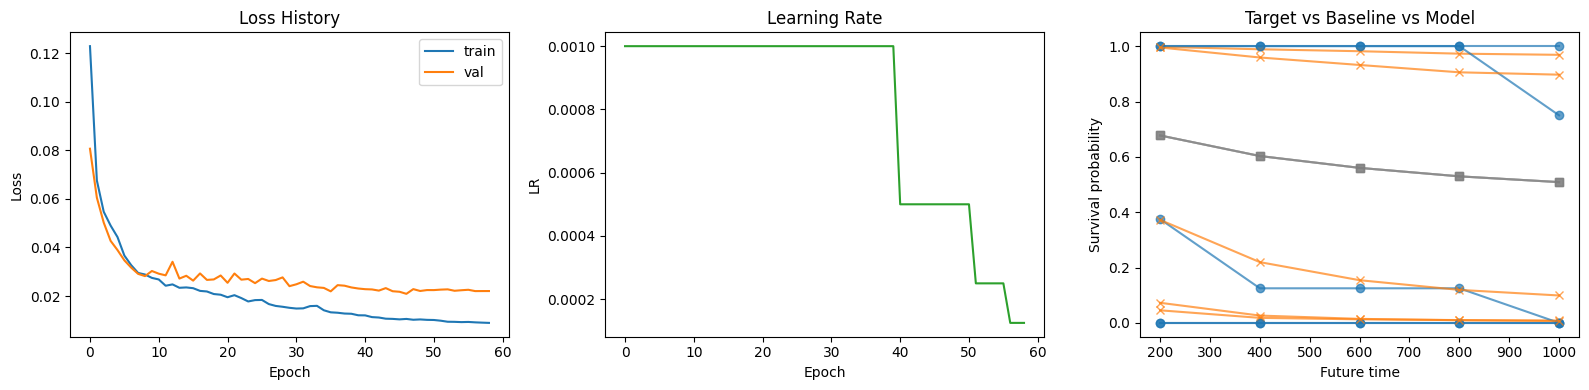

Mean training survival curve: [0.6773 0.603  0.5601 0.5296 0.5087]
Mean testing  survival curve: [0.6682 0.598  0.5556 0.5249 0.4986]


In [ ]:
val_metrics = evaluate_model(model, val_loader, criterion)
test_metrics = evaluate_model(model, test_loader, criterion)

print_metrics("MODEL VAL", val_metrics)
print()
print_metrics("MODEL TEST", test_metrics)
print()
print("Improvement over mean-curve baseline on TEST overall_mae:", baseline_test_metrics["overall_mae"] - test_metrics["overall_mae"])

fig, axes = plt.subplots(1, 3, figsize=(11, 4))

axes[0].plot(history["train_loss"], label="train")
axes[0].plot(history["val_loss"], label="val")
axes[0].set_title("Loss History")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()

axes[1].plot(history["lr"], color="tab:green")
axes[1].set_title("Learning Rate")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("LR")

example_ids = np.arange(min(5, len(test_metrics["preds"])))
for idx in example_ids:
    axes[2].plot(FUTURE_TIMES, test_metrics["targets"][idx], marker="o", alpha=0.7, color="tab:blue")
    axes[2].plot(FUTURE_TIMES, baseline_test_metrics["preds"][idx], marker="s", alpha=0.35, color="tab:gray")
    axes[2].plot(FUTURE_TIMES, test_metrics["preds"][idx], marker="x", alpha=0.7, color="tab:orange")
axes[2].set_title("Target vs Baseline vs Model")
axes[2].set_xlabel("Future time")
axes[2].set_ylabel("Survival probability")
axes[2].set_ylim(-0.05, 1.05)

plt.tight_layout()
plt.show()

print("Mean training survival curve:", np.round(y_train.mean(axis=0), 4))
print("Mean testing  survival curve:", np.round(y_test.mean(axis=0), 4))


## Hierarchical Set-Seq Model

This section keeps the 8 perturbation trajectories explicitly instead of averaging them first.

Pipeline:

1. Input: `(B, 8, 100, 15)`
2. Shared trajectory encoder: encode each of the 8 trajectories independently
3. Cross-trajectory attention aggregator: summarize the perturbation set into a case embedding
4. Monotone autoregressive decoder: predict the future survival curve


In [22]:
def build_case_set_inputs(X: np.ndarray, case_ids: np.ndarray, group_size: int = GROUP_SIZE) -> np.ndarray:
    xs = []
    for case_id in np.unique(case_ids):
        group = X[case_ids == case_id]
        if len(group) != group_size:
            raise ValueError(f"Case {case_id} has {len(group)} trajectories, expected {group_size}")
        xs.append(group)
    return np.stack(xs).astype(np.float32)


X_case_set = build_case_set_inputs(X_traj, case_ids=case_ids, group_size=GROUP_SIZE)
assert X_case_set.shape[:3] == (len(y_case), GROUP_SIZE, T_IN)
assert np.allclose(y_case, build_survival_targets(time_unbound, case_ids=case_ids, future_times=FUTURE_TIMES))

X_set_train = X_case_set[train_idx]
X_set_val = X_case_set[val_idx]
X_set_test = X_case_set[test_idx]

set_mu = X_set_train.mean(axis=(0, 1, 2), keepdims=True)
set_sd = X_set_train.std(axis=(0, 1, 2), keepdims=True) + 1e-6
X_set_train = (X_set_train - set_mu) / set_sd
X_set_val = (X_set_val - set_mu) / set_sd
X_set_test = (X_set_test - set_mu) / set_sd

print("Hierarchical inputs:")
print("  Train:", X_set_train.shape, y_train.shape)
print("  Val  :", X_set_val.shape, y_val.shape)
print("  Test :", X_set_test.shape, y_test.shape)


class SetSurvivalDataset(Dataset):
    def __init__(self, X: np.ndarray, y: np.ndarray):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.float32)

    def __len__(self):
        return self.X.shape[0]

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]


set_train_loader = DataLoader(SetSurvivalDataset(X_set_train, y_train), batch_size=BATCH_SIZE, shuffle=True)
set_val_loader = DataLoader(SetSurvivalDataset(X_set_val, y_val), batch_size=BATCH_SIZE, shuffle=False)
set_test_loader = DataLoader(SetSurvivalDataset(X_set_test, y_test), batch_size=BATCH_SIZE, shuffle=False)


Hierarchical inputs:
  Train: (3500, 8, 100, 15) (3500, 5)
  Val  : (500, 8, 100, 15) (500, 5)
  Test : (1000, 8, 100, 15) (1000, 5)


In [23]:
HIER_HIDDEN_DIM = 128
HIER_NUM_HEADS = 4
HIER_DROPOUT = 0.20
HIER_EPOCHS = 80


class SharedTrajectoryGRUEncoder(nn.Module):
    def __init__(self, input_dim: int, hidden_dim: int, dropout: float = 0.1):
        super().__init__()
        self.in_proj = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.GELU(),
            nn.Dropout(dropout),
        )
        self.gru = nn.GRU(input_size=hidden_dim, hidden_size=hidden_dim, num_layers=1, batch_first=True)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = self.in_proj(x)
        _, h_n = self.gru(x)
        return h_n[-1]


class CrossTrajectoryAttentionAggregator(nn.Module):
    def __init__(self, hidden_dim: int, num_heads: int = 4, dropout: float = 0.1):
        super().__init__()
        self.attn = nn.MultiheadAttention(
            embed_dim=hidden_dim,
            num_heads=num_heads,
            dropout=dropout,
            batch_first=True,
        )
        self.norm1 = nn.LayerNorm(hidden_dim)
        self.ffn = nn.Sequential(
            nn.Linear(hidden_dim, 2 * hidden_dim),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(2 * hidden_dim, hidden_dim),
        )
        self.norm2 = nn.LayerNorm(hidden_dim)
        self.summary_proj = nn.Sequential(
            nn.Linear(2 * hidden_dim, hidden_dim),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, hidden_dim),
        )

    def forward(self, traj_embeddings: torch.Tensor) -> tuple[torch.Tensor, torch.Tensor]:
        attn_out, attn_weights = self.attn(traj_embeddings, traj_embeddings, traj_embeddings)
        x = self.norm1(traj_embeddings + attn_out)
        x = self.norm2(x + self.ffn(x))
        mean_summary = x.mean(dim=1)
        std_summary = x.std(dim=1, unbiased=False)
        case_embedding = self.summary_proj(torch.cat([mean_summary, std_summary], dim=-1))
        return case_embedding, attn_weights


class HierarchicalSetSeqSurvivalModel(nn.Module):
    def __init__(
        self,
        input_dim: int,
        hidden_dim: int,
        horizon: int,
        num_heads: int = 4,
        dropout: float = 0.1,
    ):
        super().__init__()
        self.traj_encoder = SharedTrajectoryGRUEncoder(
            input_dim=input_dim,
            hidden_dim=hidden_dim,
            dropout=dropout,
        )
        self.set_aggregator = CrossTrajectoryAttentionAggregator(
            hidden_dim=hidden_dim,
            num_heads=num_heads,
            dropout=dropout,
        )
        self.decoder = AutoregressiveDecoder(
            hidden_dim=hidden_dim,
            horizon=horizon,
            dropout=dropout,
        )

    def forward(self, x: torch.Tensor, targets: torch.Tensor | None = None, teacher_forcing: bool = False) -> torch.Tensor:
        batch_size, group_size, seq_len, feat_dim = x.shape
        x_flat = x.view(batch_size * group_size, seq_len, feat_dim)
        traj_embeddings = self.traj_encoder(x_flat)
        traj_embeddings = traj_embeddings.view(batch_size, group_size, -1)
        case_embedding, _ = self.set_aggregator(traj_embeddings)
        return self.decoder(case_embedding, targets=targets, teacher_forcing=teacher_forcing)


@torch.no_grad()
def inspect_set_attention(model: nn.Module, x: torch.Tensor):
    model.eval()
    batch_size, group_size, seq_len, feat_dim = x.shape
    x_flat = x.view(batch_size * group_size, seq_len, feat_dim)
    traj_embeddings = model.traj_encoder(x_flat).view(batch_size, group_size, -1)
    _, attn_weights = model.set_aggregator(traj_embeddings)
    return attn_weights.detach().cpu().numpy()


epoch 001 | train_loss 0.141131 | val_loss 0.066442 | val_mae 0.173398 | lr 1.00e-03 | patience 0/12
epoch 002 | train_loss 0.061071 | val_loss 0.048939 | val_mae 0.148495 | lr 1.00e-03 | patience 0/12
epoch 003 | train_loss 0.045161 | val_loss 0.043151 | val_mae 0.128239 | lr 1.00e-03 | patience 0/12
epoch 004 | train_loss 0.039756 | val_loss 0.032721 | val_mae 0.109275 | lr 1.00e-03 | patience 0/12
epoch 005 | train_loss 0.034995 | val_loss 0.027055 | val_mae 0.103571 | lr 1.00e-03 | patience 0/12
epoch 006 | train_loss 0.029274 | val_loss 0.023012 | val_mae 0.092919 | lr 1.00e-03 | patience 0/12
epoch 007 | train_loss 0.024469 | val_loss 0.030779 | val_mae 0.109049 | lr 1.00e-03 | patience 1/12
epoch 008 | train_loss 0.024002 | val_loss 0.021942 | val_mae 0.088851 | lr 1.00e-03 | patience 0/12
epoch 009 | train_loss 0.020529 | val_loss 0.021451 | val_mae 0.085512 | lr 1.00e-03 | patience 0/12
epoch 010 | train_loss 0.020954 | val_loss 0.022302 | val_mae 0.088875 | lr 1.00e-03 | pati

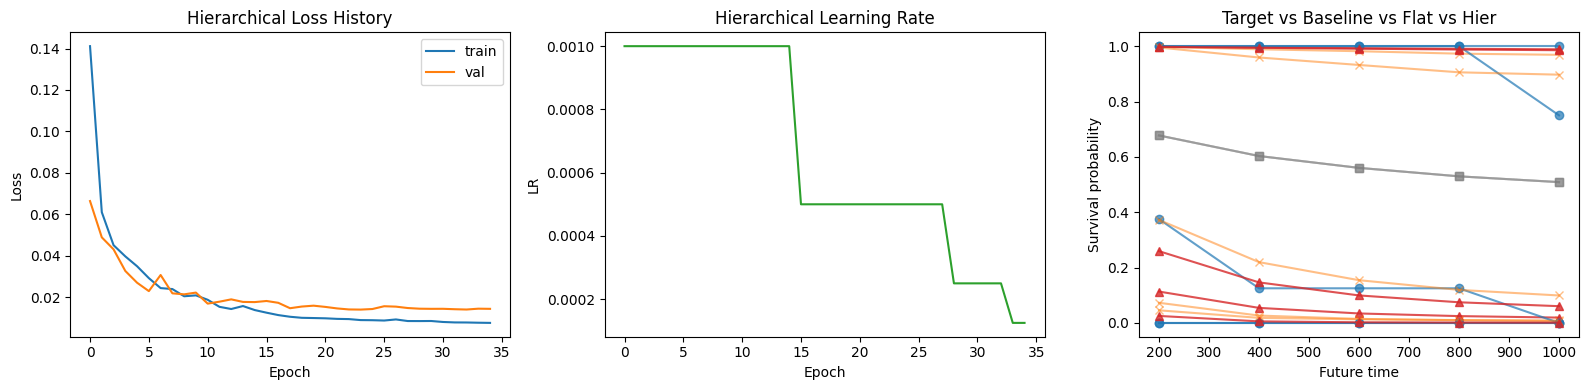

Example cross-trajectory attention shape: (1, 8, 8)


In [ ]:
hier_model = HierarchicalSetSeqSurvivalModel(
    input_dim=NUM_FEATURES,
    hidden_dim=HIER_HIDDEN_DIM,
    horizon=len(FUTURE_TIMES),
    num_heads=HIER_NUM_HEADS,
    dropout=HIER_DROPOUT,
).to(DEVICE)

hier_model, hier_history, hier_fit_info = train_model(
    hier_model,
    train_loader=set_train_loader,
    val_loader=set_val_loader,
    criterion=criterion,
    epochs=HIER_EPOCHS,
    lr=LR,
    weight_decay=WEIGHT_DECAY,
    grad_clip_norm=GRAD_CLIP_NORM,
    teacher_forcing_ratio=TEACHER_FORCING_RATIO,
    scheduler_patience=SCHEDULER_PATIENCE,
    scheduler_factor=SCHEDULER_FACTOR,
    early_stopping_patience=EARLY_STOPPING_PATIENCE,
    early_stopping_min_delta=EARLY_STOPPING_MIN_DELTA,
)

hier_val_metrics = evaluate_model(hier_model, set_val_loader, criterion)
hier_test_metrics = evaluate_model(hier_model, set_test_loader, criterion)

print("Hierarchical fit info:", hier_fit_info)
print()
print_metrics("HIER VAL", hier_val_metrics)
print()
print_metrics("HIER TEST", hier_test_metrics)
print()
print("Improvement over mean baseline on TEST overall_mae:", baseline_test_metrics["overall_mae"] - hier_test_metrics["overall_mae"])
print("Improvement over flat case model on TEST overall_mae:", test_metrics["overall_mae"] - hier_test_metrics["overall_mae"])

fig, axes = plt.subplots(1, 3, figsize=(11, 4))

axes[0].plot(hier_history["train_loss"], label="train")
axes[0].plot(hier_history["val_loss"], label="val")
axes[0].set_title("Hierarchical Loss History")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()

axes[1].plot(hier_history["lr"], color="tab:green")
axes[1].set_title("Hierarchical Learning Rate")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("LR")

example_ids = np.arange(min(5, len(hier_test_metrics["preds"])))
for idx in example_ids:
    axes[2].plot(FUTURE_TIMES, hier_test_metrics["targets"][idx], marker="o", alpha=0.7, color="tab:blue")
    axes[2].plot(FUTURE_TIMES, baseline_test_metrics["preds"][idx], marker="s", alpha=0.25, color="tab:gray")
    axes[2].plot(FUTURE_TIMES, test_metrics["preds"][idx], marker="x", alpha=0.5, color="tab:orange")
    axes[2].plot(FUTURE_TIMES, hier_test_metrics["preds"][idx], marker="^", alpha=0.8, color="tab:red")
axes[2].set_title("Target vs Baseline vs Flat vs Hier")
axes[2].set_xlabel("Future time")
axes[2].set_ylabel("Survival probability")
axes[2].set_ylim(-0.05, 1.05)

plt.tight_layout()
plt.show()

attn_example = torch.tensor(X_set_test[:1], dtype=torch.float32, device=DEVICE)
attn_weights = inspect_set_attention(hier_model, attn_example)
print("Example cross-trajectory attention shape:", attn_weights.shape)


## Temporal + Set Dual Attention Model

This experiment upgrades the trajectory encoder from GRU to temporal self-attention, while keeping the set-level cross-trajectory attention and the monotone autoregressive decoder.

Pipeline:

1. Temporal self-attention inside each trajectory: `(100, 15) -> d`
2. Set attention across the 8 perturbation trajectories: `(8, d) -> d_case`
3. Monotone autoregressive decoder: `d_case -> survival curve`


In [25]:
DUAL_HIDDEN_DIM = 128
DUAL_NUM_HEADS_TEMPORAL = 4
DUAL_NUM_HEADS_SET = 4
DUAL_NUM_TEMPORAL_LAYERS = 2
DUAL_DROPOUT = 0.20
DUAL_EPOCHS = 80


class SinusoidalPositionalEncoding(nn.Module):
    def __init__(self, d_model: int, max_len: int = 512):
        super().__init__()
        pe = torch.zeros(max_len, d_model)
        position = torch.arange(0, max_len, dtype=torch.float32).unsqueeze(1)
        div_term = torch.exp(torch.arange(0, d_model, 2, dtype=torch.float32) * (-np.log(10000.0) / d_model))
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        self.register_buffer("pe", pe.unsqueeze(0))

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return x + self.pe[:, :x.size(1), :]


class TemporalSelfAttentionTrajectoryEncoder(nn.Module):
    def __init__(
        self,
        input_dim: int,
        hidden_dim: int,
        num_heads: int = 4,
        num_layers: int = 2,
        dropout: float = 0.1,
        max_len: int = 256,
    ):
        super().__init__()
        self.input_proj = nn.Linear(input_dim, hidden_dim)
        self.cls_token = nn.Parameter(torch.zeros(1, 1, hidden_dim))
        self.pos_enc = SinusoidalPositionalEncoding(hidden_dim, max_len=max_len + 1)
        self.dropout = nn.Dropout(dropout)

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=hidden_dim,
            nhead=num_heads,
            dim_feedforward=4 * hidden_dim,
            dropout=dropout,
            activation="gelu",
            batch_first=True,
            norm_first=True,
        )
        self.encoder = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)
        self.out_norm = nn.LayerNorm(hidden_dim)

        nn.init.normal_(self.cls_token, mean=0.0, std=0.02)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # x: (N, T, F)
        x = self.input_proj(x)
        cls = self.cls_token.expand(x.size(0), -1, -1)
        x = torch.cat([cls, x], dim=1)
        x = self.pos_enc(x)
        x = self.dropout(x)
        x = self.encoder(x)
        return self.out_norm(x[:, 0, :])


class DualAttentionSetSeqSurvivalModel(nn.Module):
    def __init__(
        self,
        input_dim: int,
        hidden_dim: int,
        horizon: int,
        temporal_heads: int = 4,
        temporal_layers: int = 2,
        set_heads: int = 4,
        dropout: float = 0.1,
    ):
        super().__init__()
        self.traj_encoder = TemporalSelfAttentionTrajectoryEncoder(
            input_dim=input_dim,
            hidden_dim=hidden_dim,
            num_heads=temporal_heads,
            num_layers=temporal_layers,
            dropout=dropout,
            max_len=T_IN,
        )
        self.set_aggregator = CrossTrajectoryAttentionAggregator(
            hidden_dim=hidden_dim,
            num_heads=set_heads,
            dropout=dropout,
        )
        self.decoder = AutoregressiveDecoder(
            hidden_dim=hidden_dim,
            horizon=horizon,
            dropout=dropout,
        )

    def forward(self, x: torch.Tensor, targets: torch.Tensor | None = None, teacher_forcing: bool = False) -> torch.Tensor:
        batch_size, group_size, seq_len, feat_dim = x.shape
        x_flat = x.view(batch_size * group_size, seq_len, feat_dim)
        traj_embeddings = self.traj_encoder(x_flat).view(batch_size, group_size, -1)
        case_embedding, _ = self.set_aggregator(traj_embeddings)
        return self.decoder(case_embedding, targets=targets, teacher_forcing=teacher_forcing)


/tmp/ipykernel_240136/2730071427.py:48: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.encoder = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)


epoch 001 | train_loss 0.183246 | val_loss 0.124371 | val_mae 0.319534 | lr 1.00e-03 | patience 0/12
epoch 002 | train_loss 0.090584 | val_loss 0.059235 | val_mae 0.160530 | lr 1.00e-03 | patience 0/12
epoch 003 | train_loss 0.051714 | val_loss 0.030708 | val_mae 0.115267 | lr 1.00e-03 | patience 0/12
epoch 004 | train_loss 0.032718 | val_loss 0.022417 | val_mae 0.089494 | lr 1.00e-03 | patience 0/12
epoch 005 | train_loss 0.026135 | val_loss 0.023838 | val_mae 0.087894 | lr 1.00e-03 | patience 1/12
epoch 006 | train_loss 0.020918 | val_loss 0.017926 | val_mae 0.077441 | lr 1.00e-03 | patience 0/12
epoch 007 | train_loss 0.021086 | val_loss 0.016682 | val_mae 0.072574 | lr 1.00e-03 | patience 0/12
epoch 008 | train_loss 0.016030 | val_loss 0.017679 | val_mae 0.073816 | lr 1.00e-03 | patience 1/12
epoch 009 | train_loss 0.016429 | val_loss 0.016676 | val_mae 0.073220 | lr 1.00e-03 | patience 2/12
epoch 010 | train_loss 0.014869 | val_loss 0.015547 | val_mae 0.068709 | lr 1.00e-03 | pati

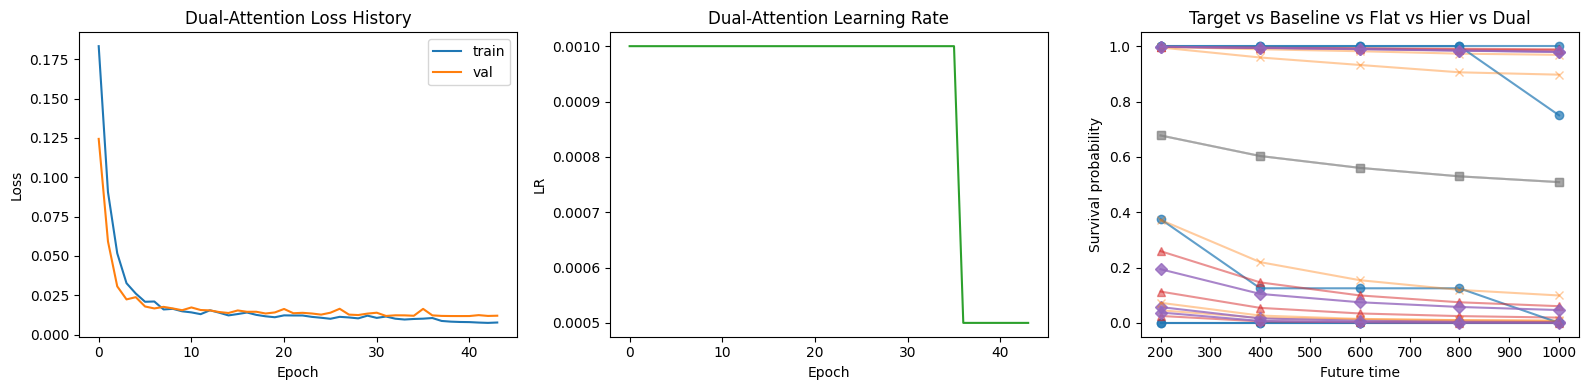

In [26]:
dual_model = DualAttentionSetSeqSurvivalModel(
    input_dim=NUM_FEATURES,
    hidden_dim=DUAL_HIDDEN_DIM,
    horizon=len(FUTURE_TIMES),
    temporal_heads=DUAL_NUM_HEADS_TEMPORAL,
    temporal_layers=DUAL_NUM_TEMPORAL_LAYERS,
    set_heads=DUAL_NUM_HEADS_SET,
    dropout=DUAL_DROPOUT,
).to(DEVICE)

dual_model, dual_history, dual_fit_info = train_model(
    dual_model,
    train_loader=set_train_loader,
    val_loader=set_val_loader,
    criterion=criterion,
    epochs=DUAL_EPOCHS,
    lr=LR,
    weight_decay=WEIGHT_DECAY,
    grad_clip_norm=GRAD_CLIP_NORM,
    teacher_forcing_ratio=TEACHER_FORCING_RATIO,
    scheduler_patience=SCHEDULER_PATIENCE,
    scheduler_factor=SCHEDULER_FACTOR,
    early_stopping_patience=EARLY_STOPPING_PATIENCE,
    early_stopping_min_delta=EARLY_STOPPING_MIN_DELTA,
)

dual_val_metrics = evaluate_model(dual_model, set_val_loader, criterion)
dual_test_metrics = evaluate_model(dual_model, set_test_loader, criterion)

print("Dual-attention fit info:", dual_fit_info)
print()
print_metrics("DUAL VAL", dual_val_metrics)
print()
print_metrics("DUAL TEST", dual_test_metrics)
print()
print("Improvement over mean baseline on TEST overall_mae:", baseline_test_metrics["overall_mae"] - dual_test_metrics["overall_mae"])
print("Improvement over flat case model on TEST overall_mae:", test_metrics["overall_mae"] - dual_test_metrics["overall_mae"])
print("Improvement over hierarchical set-seq model on TEST overall_mae:", hier_test_metrics["overall_mae"] - dual_test_metrics["overall_mae"])

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(dual_history["train_loss"], label="train")
axes[0].plot(dual_history["val_loss"], label="val")
axes[0].set_title("Dual-Attention Loss History")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()

axes[1].plot(dual_history["lr"], color="tab:green")
axes[1].set_title("Dual-Attention Learning Rate")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("LR")

plt.tight_layout()
plt.show()

example_ids = np.arange(min(5, len(dual_test_metrics["preds"])))
fig, example_axes = plt.subplots(len(example_ids), 1, figsize=(8, 2.8 * len(example_ids)), sharex=True)
if len(example_ids) == 1:
    example_axes = [example_axes]

model_styles = [
    ("Target", dual_test_metrics["targets"], "tab:blue", "o", "-", 2.4),
    ("Mean Baseline", baseline_test_metrics["preds"], "tab:gray", "s", "--", 1.8),
    ("Flat GRU Seq2Seq", test_metrics["preds"], "tab:orange", "x", "-.", 1.8),
    ("Hierarchical Set-Seq", hier_test_metrics["preds"], "tab:red", "^", "-", 1.8),
    ("Dual Attention", dual_test_metrics["preds"], "tab:purple", "D", "-", 2.0),
]

for ax, idx in zip(example_axes, example_ids):
    for label, values, color, marker, linestyle, linewidth in model_styles:
        ax.plot(
            FUTURE_TIMES,
            values[idx],
            label=label,
            color=color,
            marker=marker,
            linestyle=linestyle,
            linewidth=linewidth,
            markersize=6,
            alpha=0.95,
        )
    ax.set_title(f"Example case {idx}")
    ax.set_ylabel("Survival")
    ax.set_ylim(-0.05, 1.05)
    ax.grid(True, alpha=0.25, linestyle=":")
    ax.legend(loc="center left", bbox_to_anchor=(1.02, 0.5), frameon=True)

example_axes[-1].set_xlabel("Future time")
fig.suptitle("Per-Case Survival Curves: Target vs Model Predictions", y=1.02)
plt.tight_layout()
plt.show()


# NEW APPENDED SECTION: Hazard-Rate Hierarchical Set-Seq Model

Run the next two code cells in order. This is the newly appended hazard-rate pipeline.

This experiment keeps the same case-level set input `(B, 8, 100, 15)` as the hierarchical model, but rewrites the decoder in standard discrete-time survival-analysis form.

- Predict a per-horizon hazard rate `h_k in [0, 1]`
- Interpret `h_k` as the conditional instability risk in interval `k-1 -> k`
- Recover the survival curve by recurrence: `S_k = S_{k-1} * (1 - h_k)`, with `S_0 = 1`

This keeps the hard monotonicity constraint, but makes it easier to inspect whether the model is placing sharp failure risk on specific future windows.


In [28]:
HAZARD_HIDDEN_DIM = 128
HAZARD_NUM_HEADS = 4
HAZARD_DROPOUT = 0.20
HAZARD_EPOCHS = 80


class HazardRateDecoder(nn.Module):
    def __init__(self, hidden_dim: int, horizon: int, dropout: float = 0.1):
        super().__init__()
        self.horizon = horizon
        self.step_embed = nn.Embedding(horizon, hidden_dim)
        self.input_proj = nn.Sequential(
            nn.Linear(hidden_dim + 1, hidden_dim),
            nn.GELU(),
            nn.Dropout(dropout),
        )
        self.gru_cell = nn.GRUCell(input_size=hidden_dim, hidden_size=hidden_dim)
        self.hidden_norm = nn.LayerNorm(hidden_dim)
        self.hazard_head = nn.Sequential(
            nn.Linear(2 * hidden_dim + 1, hidden_dim),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, 1),
        )

    def forward(
        self,
        context: torch.Tensor,
        targets: torch.Tensor | None = None,
        teacher_forcing: bool = False,
        return_hazard: bool = False,
    ):
        batch_size = context.size(0)
        hidden = context
        prev_survival = torch.ones(batch_size, 1, device=context.device, dtype=context.dtype)
        survival_preds = []
        hazard_preds = []

        for step in range(self.horizon):
            step_ids = torch.full((batch_size,), step, device=context.device, dtype=torch.long)
            step_feat = self.step_embed(step_ids)
            decoder_in = self.input_proj(torch.cat([prev_survival, step_feat], dim=-1))
            hidden = self.hidden_norm(self.gru_cell(decoder_in, hidden))
            hazard_logits = self.hazard_head(torch.cat([hidden, step_feat, prev_survival], dim=-1))
            hazard = torch.sigmoid(hazard_logits)
            survival_t = prev_survival * (1.0 - hazard)
            hazard_preds.append(hazard)
            survival_preds.append(survival_t)

            if teacher_forcing and targets is not None:
                prev_survival = targets[:, step:step + 1]
            else:
                prev_survival = survival_t

        survival = torch.cat(survival_preds, dim=1)
        hazard = torch.cat(hazard_preds, dim=1)
        if return_hazard:
            return survival, hazard
        return survival


class HazardHierarchicalSetSeqModel(nn.Module):
    def __init__(
        self,
        input_dim: int,
        hidden_dim: int,
        horizon: int,
        num_heads: int = 4,
        dropout: float = 0.1,
    ):
        super().__init__()
        self.traj_encoder = SharedTrajectoryGRUEncoder(
            input_dim=input_dim,
            hidden_dim=hidden_dim,
            dropout=dropout,
        )
        self.set_aggregator = CrossTrajectoryAttentionAggregator(
            hidden_dim=hidden_dim,
            num_heads=num_heads,
            dropout=dropout,
        )
        self.decoder = HazardRateDecoder(
            hidden_dim=hidden_dim,
            horizon=horizon,
            dropout=dropout,
        )

    def forward(
        self,
        x: torch.Tensor,
        targets: torch.Tensor | None = None,
        teacher_forcing: bool = False,
        return_hazard: bool = False,
    ):
        batch_size, group_size, seq_len, feat_dim = x.shape
        x_flat = x.view(batch_size * group_size, seq_len, feat_dim)
        traj_embeddings = self.traj_encoder(x_flat)
        traj_embeddings = traj_embeddings.view(batch_size, group_size, -1)
        case_embedding, _ = self.set_aggregator(traj_embeddings)
        return self.decoder(
            case_embedding,
            targets=targets,
            teacher_forcing=teacher_forcing,
            return_hazard=return_hazard,
        )


@torch.no_grad()
def evaluate_hazard_model(model, loader, criterion):
    model.eval()
    losses = []
    preds_all = []
    hazards_all = []
    targets_all = []

    for xb, yb in loader:
        xb = xb.to(DEVICE)
        yb = yb.to(DEVICE)
        pred, hazard = model(xb, return_hazard=True)
        loss = criterion(pred, yb)
        losses.append(float(loss.item()))
        preds_all.append(pred.detach().cpu())
        hazards_all.append(hazard.detach().cpu())
        targets_all.append(yb.detach().cpu())

    preds = torch.cat(preds_all, dim=0).numpy()
    hazards = torch.cat(hazards_all, dim=0).numpy()
    targets = torch.cat(targets_all, dim=0).numpy()
    mae_per_horizon = np.mean(np.abs(preds - targets), axis=0)
    mse_per_horizon = np.mean((preds - targets) ** 2, axis=0)
    overall_mae = float(np.mean(np.abs(preds - targets)))
    monotone_fraction = float(np.mean(np.all(preds[:, 1:] <= preds[:, :-1] + 1e-6, axis=1)))

    return {
        "loss": float(np.mean(losses)),
        "overall_mae": overall_mae,
        "mae_per_horizon": mae_per_horizon,
        "mse_per_horizon": mse_per_horizon,
        "monotone_fraction": monotone_fraction,
        "preds": preds,
        "hazards": hazards,
        "targets": targets,
    }


epoch 001 | train_loss 0.129863 | val_loss 0.072531 | val_mae 0.175112 | lr 1.00e-03 | patience 0/12
epoch 002 | train_loss 0.055889 | val_loss 0.049446 | val_mae 0.150545 | lr 1.00e-03 | patience 0/12
epoch 003 | train_loss 0.044400 | val_loss 0.038235 | val_mae 0.132192 | lr 1.00e-03 | patience 0/12
epoch 004 | train_loss 0.038809 | val_loss 0.038314 | val_mae 0.120176 | lr 1.00e-03 | patience 1/12
epoch 005 | train_loss 0.035842 | val_loss 0.031007 | val_mae 0.105955 | lr 1.00e-03 | patience 0/12
epoch 006 | train_loss 0.028765 | val_loss 0.031564 | val_mae 0.102276 | lr 1.00e-03 | patience 1/12
epoch 007 | train_loss 0.025591 | val_loss 0.025708 | val_mae 0.091917 | lr 1.00e-03 | patience 0/12
epoch 008 | train_loss 0.022666 | val_loss 0.021093 | val_mae 0.085850 | lr 1.00e-03 | patience 0/12
epoch 009 | train_loss 0.021218 | val_loss 0.026037 | val_mae 0.092523 | lr 1.00e-03 | patience 1/12
epoch 010 | train_loss 0.020392 | val_loss 0.020731 | val_mae 0.082816 | lr 1.00e-03 | pati

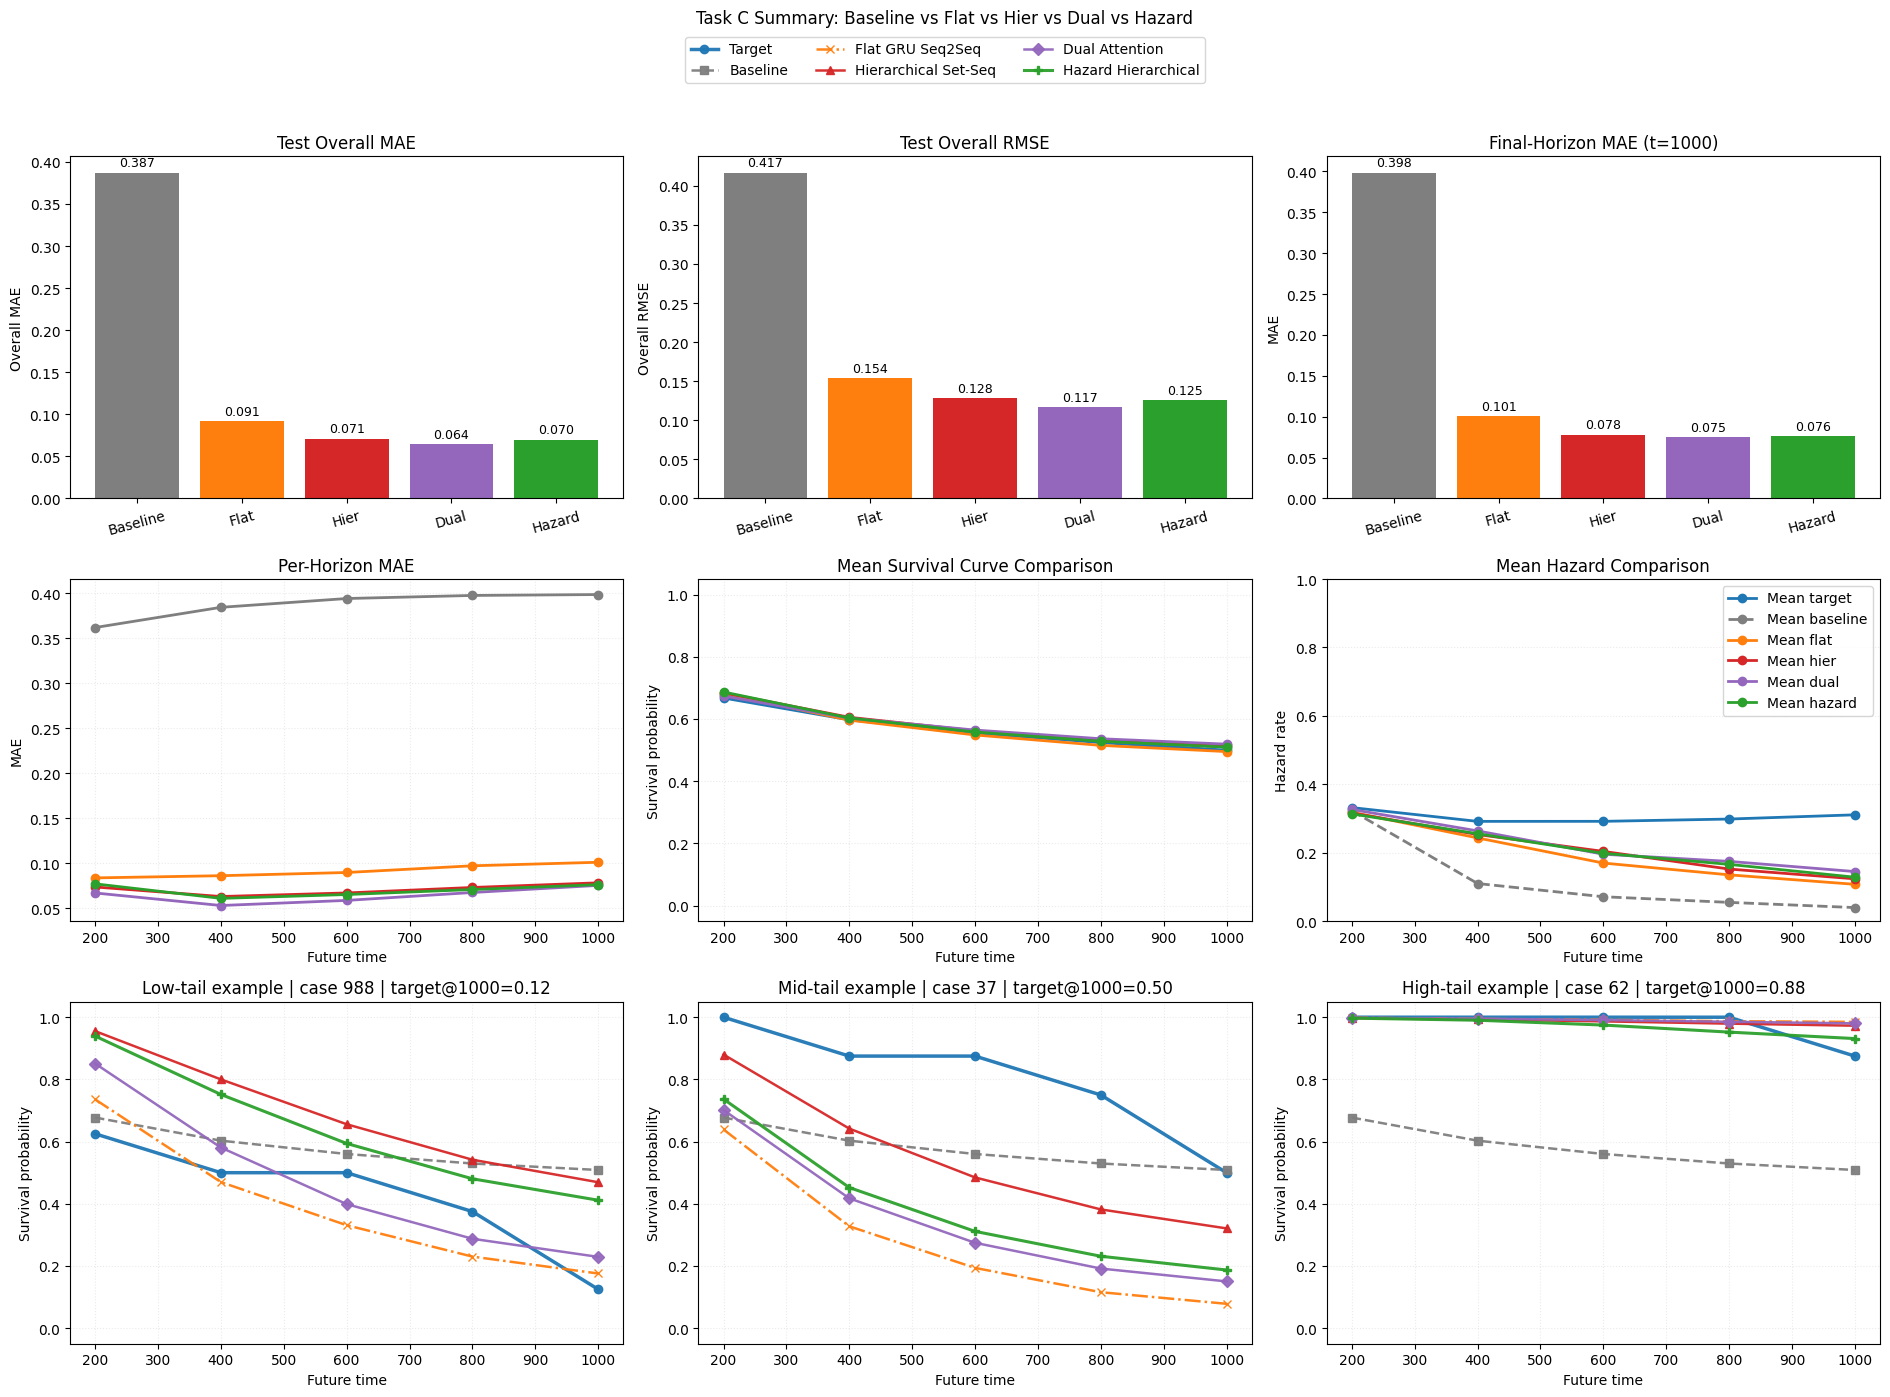

In [20]:
hazard_model = HazardHierarchicalSetSeqModel(
    input_dim=NUM_FEATURES,
    hidden_dim=HAZARD_HIDDEN_DIM,
    horizon=len(FUTURE_TIMES),
    num_heads=HAZARD_NUM_HEADS,
    dropout=HAZARD_DROPOUT,
).to(DEVICE)

hazard_model, hazard_history, hazard_fit_info = train_model(
    hazard_model,
    train_loader=set_train_loader,
    val_loader=set_val_loader,
    criterion=criterion,
    epochs=HAZARD_EPOCHS,
    lr=LR,
    weight_decay=WEIGHT_DECAY,
    grad_clip_norm=GRAD_CLIP_NORM,
    teacher_forcing_ratio=TEACHER_FORCING_RATIO,
    scheduler_patience=SCHEDULER_PATIENCE,
    scheduler_factor=SCHEDULER_FACTOR,
    early_stopping_patience=EARLY_STOPPING_PATIENCE,
    early_stopping_min_delta=EARLY_STOPPING_MIN_DELTA,
)

hazard_val_metrics = evaluate_hazard_model(hazard_model, set_val_loader, criterion)
hazard_test_metrics = evaluate_hazard_model(hazard_model, set_test_loader, criterion)

print("Hazard fit info:", hazard_fit_info)
print()
print_metrics("HAZARD VAL", hazard_val_metrics)
print()
print_metrics("HAZARD TEST", hazard_test_metrics)
print()
print("Improvement over mean baseline on TEST overall_mae:", baseline_test_metrics["overall_mae"] - hazard_test_metrics["overall_mae"])
print("Improvement over flat case model on TEST overall_mae:", test_metrics["overall_mae"] - hazard_test_metrics["overall_mae"])
print("Improvement over hierarchical set-seq model on TEST overall_mae:", hier_test_metrics["overall_mae"] - hazard_test_metrics["overall_mae"])
print("Improvement over dual-attention model on TEST overall_mae:", dual_test_metrics["overall_mae"] - hazard_test_metrics["overall_mae"])
print("Mean predicted hazard per horizon:", np.round(hazard_test_metrics["hazards"].mean(axis=0), 6))

comparison_metrics = {
    "Baseline": baseline_test_metrics,
    "Flat": test_metrics,
    "Hier": hier_test_metrics,
    "Dual": dual_test_metrics,
    "Hazard": hazard_test_metrics,
}
comparison_colors = {
    "Baseline": "tab:gray",
    "Flat": "tab:orange",
    "Hier": "tab:red",
    "Dual": "tab:purple",
    "Hazard": "tab:green",
}

summary_rows = []
for name, metrics in comparison_metrics.items():
    preds = metrics["preds"]
    targets_ref = metrics["targets"]
    summary_rows.append({
        "model": name,
        "overall_mae": metrics["overall_mae"],
        "overall_rmse": float(np.sqrt(np.mean((preds - targets_ref) ** 2))),
        "final_horizon_mae": float(np.mean(np.abs(preds[:, -1] - targets_ref[:, -1]))),
        "mean_curve_gap": float(np.mean(np.abs(preds.mean(axis=0) - targets_ref.mean(axis=0)))),
    })

summary_df = pd.DataFrame(summary_rows).set_index("model")
print("Expanded test metric summary:")
print(summary_df.round(4).to_string())
print()

comparison_names = list(comparison_metrics.keys())
comparison_overall_mae = summary_df.loc[comparison_names, "overall_mae"].to_numpy()
comparison_overall_rmse = summary_df.loc[comparison_names, "overall_rmse"].to_numpy()
comparison_final_mae = summary_df.loc[comparison_names, "final_horizon_mae"].to_numpy()
comparison_mae_per_horizon = {
    name: metrics["mae_per_horizon"]
    for name, metrics in comparison_metrics.items()
}
def survival_to_hazard(curves: np.ndarray) -> np.ndarray:
    prev_survival = np.concatenate(
        [np.ones((curves.shape[0], 1), dtype=curves.dtype), curves[:, :-1]],
        axis=1,
    )
    hazard = 1.0 - np.clip(curves / np.clip(prev_survival, 1e-6, None), 0.0, 1.0)
    return np.clip(hazard, 0.0, 1.0)

mean_hazard_curves = {
    "Target": survival_to_hazard(hazard_test_metrics["targets"]).mean(axis=0),
    "Baseline": survival_to_hazard(baseline_test_metrics["preds"]).mean(axis=0),
    "Flat": survival_to_hazard(test_metrics["preds"]).mean(axis=0),
    "Hier": survival_to_hazard(hier_test_metrics["preds"]).mean(axis=0),
    "Dual": survival_to_hazard(dual_test_metrics["preds"]).mean(axis=0),
    "Hazard": hazard_test_metrics["hazards"].mean(axis=0),
}

targets = hazard_test_metrics["targets"]
tail_targets = targets[:, -1]
desired_tail_levels = [0.15, 0.50, 0.85]
example_titles = ["Low-tail", "Mid-tail", "High-tail"]
example_indices = []
used_example_indices = set()
for desired in desired_tail_levels:
    ordered = np.argsort(np.abs(tail_targets - desired))
    for idx in ordered:
        idx = int(idx)
        if idx not in used_example_indices:
            example_indices.append(idx)
            used_example_indices.add(idx)
            break

summary_styles = [
    ("Target", hazard_test_metrics["targets"], "tab:blue", "o", "-", 2.5),
    ("Baseline", baseline_test_metrics["preds"], "tab:gray", "s", "--", 1.8),
    ("Flat GRU Seq2Seq", test_metrics["preds"], "tab:orange", "x", "-.", 1.8),
    ("Hierarchical Set-Seq", hier_test_metrics["preds"], "tab:red", "^", "-", 1.8),
    ("Dual Attention", dual_test_metrics["preds"], "tab:purple", "D", "-", 1.8),
    ("Hazard Hierarchical", hazard_test_metrics["preds"], "tab:green", "P", "-", 2.2),
]

fig, axes = plt.subplots(3, 3, figsize=(19, 14))
comparison_bar_colors = [comparison_colors[name] for name in comparison_names]

axes[0, 0].bar(comparison_names, comparison_overall_mae, color=comparison_bar_colors)
axes[0, 0].set_title("Test Overall MAE")
axes[0, 0].set_ylabel("Overall MAE")
axes[0, 0].tick_params(axis="x", rotation=15)
for i, value in enumerate(comparison_overall_mae):
    axes[0, 0].text(i, value + 0.004, f"{value:.3f}", ha="center", va="bottom", fontsize=9)

axes[0, 1].bar(comparison_names, comparison_overall_rmse, color=comparison_bar_colors)
axes[0, 1].set_title("Test Overall RMSE")
axes[0, 1].set_ylabel("Overall RMSE")
axes[0, 1].tick_params(axis="x", rotation=15)
for i, value in enumerate(comparison_overall_rmse):
    axes[0, 1].text(i, value + 0.004, f"{value:.3f}", ha="center", va="bottom", fontsize=9)

axes[0, 2].bar(comparison_names, comparison_final_mae, color=comparison_bar_colors)
axes[0, 2].set_title(f"Final-Horizon MAE (t={int(FUTURE_TIMES[-1])})")
axes[0, 2].set_ylabel("MAE")
axes[0, 2].tick_params(axis="x", rotation=15)
for i, value in enumerate(comparison_final_mae):
    axes[0, 2].text(i, value + 0.004, f"{value:.3f}", ha="center", va="bottom", fontsize=9)

for name, values in comparison_mae_per_horizon.items():
    axes[1, 0].plot(FUTURE_TIMES, values, marker="o", linewidth=2, label=name, color=comparison_colors[name])
axes[1, 0].set_title("Per-Horizon MAE")
axes[1, 0].set_xlabel("Future time")
axes[1, 0].set_ylabel("MAE")
axes[1, 0].grid(True, alpha=0.25, linestyle=":")

axes[1, 1].plot(FUTURE_TIMES, hazard_test_metrics["targets"].mean(axis=0), marker="o", linewidth=2.4, color="tab:blue", label="Mean target")
for name, metrics in comparison_metrics.items():
    axes[1, 1].plot(
        FUTURE_TIMES,
        metrics["preds"].mean(axis=0),
        marker="o",
        linewidth=2,
        linestyle="--" if name == "Baseline" else "-",
        color=comparison_colors[name],
        label=f"Mean {name.lower()}",
    )
axes[1, 1].set_title("Mean Survival Curve Comparison")
axes[1, 1].set_xlabel("Future time")
axes[1, 1].set_ylabel("Survival probability")
axes[1, 1].set_ylim(-0.05, 1.05)
axes[1, 1].grid(True, alpha=0.25, linestyle=":")

for name, values in mean_hazard_curves.items():
    axes[1, 2].plot(
        FUTURE_TIMES,
        values,
        marker="o",
        linewidth=2,
        linestyle="--" if name == "Baseline" else "-",
        color="tab:blue" if name == "Target" else comparison_colors[name],
        label=f"Mean {name.lower()}" if name != "Target" else "Mean target",
    )
axes[1, 2].set_title("Mean Hazard Comparison")
axes[1, 2].set_xlabel("Future time")
axes[1, 2].set_ylabel("Hazard rate")
axes[1, 2].set_ylim(0.0, 1.0)
axes[1, 2].grid(True, axis="y", alpha=0.25, linestyle=":")
axes[1, 2].legend()

for ax, case_label, idx in zip(axes[2], example_titles, example_indices):
    for label, values, color, marker, linestyle, linewidth in summary_styles:
        ax.plot(
            FUTURE_TIMES,
            values[idx],
            label=label,
            color=color,
            marker=marker,
            linestyle=linestyle,
            linewidth=linewidth,
            markersize=6,
            alpha=0.95,
        )
    ax.set_title(
        f"{case_label} example | case {idx} | target@{int(FUTURE_TIMES[-1])}={targets[idx, -1]:.2f}"
    )
    ax.set_xlabel("Future time")
    ax.set_ylabel("Survival probability")
    ax.set_ylim(-0.05, 1.05)
    ax.grid(True, alpha=0.25, linestyle=":")

handles, labels = axes[2, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=3, frameon=True, bbox_to_anchor=(0.5, 0.98))
fig.suptitle("Task C Summary: Baseline vs Flat vs Hier vs Dual vs Hazard", y=0.995)
plt.tight_layout(rect=(0, 0, 1, 0.94))
plt.show()
